# 02 · Preprocessing
Band-pass filter → cut beats at R-peaks → RR features → per-beat z-score → save patient-disjoint train/val/test.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')

!pip install -q wfdb
import os, json
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

from config import *
print("Train:", len(TRAIN_RECORDS), "| Val:", len(VAL_RECORDS), "| Test:", len(TEST_RECORDS))

Mounted at /content/drive
Train: 17 | Val: 5 | Test: 21


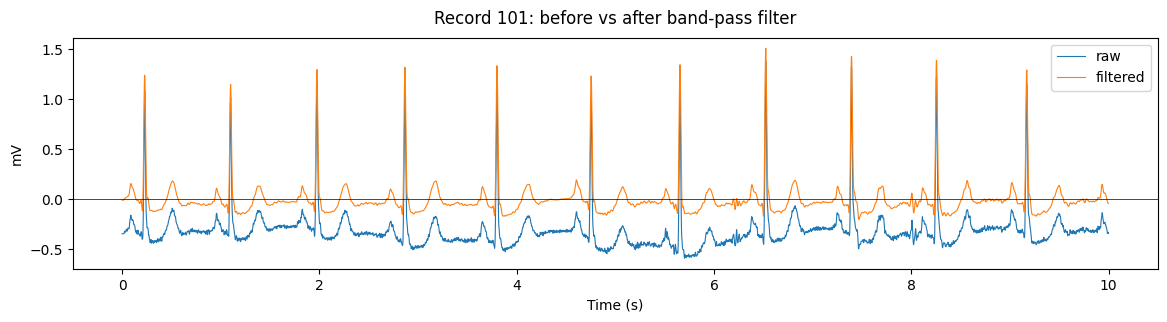

In [2]:
def bandpass(sig, low=0.5, high=40, fs=FS, order=3):
    b, a = butter(order, [low / (fs / 2), high / (fs / 2)], btype='band')
    return filtfilt(b, a, sig)          # forward + backward = no time shift

rec = wfdb.rdrecord(f'{RAW_DIR}/101')
raw = rec.p_signal[:, rec.sig_name.index(LEAD)]
clean = bandpass(raw)

t = np.arange(10 * FS) / FS
plt.figure(figsize=(14, 3))
plt.plot(t, raw[:10 * FS], lw=0.8, label='raw')
plt.plot(t, clean[:10 * FS], lw=0.8, label='filtered')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('Time (s)'); plt.ylabel('mV'); plt.legend()
plt.title('Record 101: before vs after band-pass filter', pad=10)
plt.savefig(f'{FIG_DIR}/05_filter_before_after.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
BEAT_SYMBOLS = set(AAMI.keys())   # real beat labels only (ignores '+', '~', ...)

def process_record(rid):
    rec = wfdb.rdrecord(f'{RAW_DIR}/{rid}')
    ann = wfdb.rdann(f'{RAW_DIR}/{rid}', 'atr')
    sig = bandpass(rec.p_signal[:, rec.sig_name.index(LEAD)])

    keep  = [i for i, s in enumerate(ann.symbol) if s in BEAT_SYMBOLS]
    peaks = ann.sample[keep]
    syms  = [ann.symbol[i] for i in keep]
    rr    = np.diff(peaks) / FS        # rr[i] = seconds between beat i and beat i+1

    X, cls, feats, pos = [], [], [], []
    for i in range(1, len(peaks) - 1):             # need a previous AND a next beat
        c = AAMI[syms[i]]
        if c == 'Q':
            continue                                # excluded, but still counted for RR
        p = peaks[i]
        if p - BEFORE < 0 or p + AFTER > len(sig):
            continue

        pre_rr, post_rr = rr[i - 1], rr[i]
        local_rr = rr[max(0, i - 10):i].mean()          # short-term: last 10 beats
        long_rr  = np.median(rr[max(0, i - 300):i])     # long-term: last ~5 min, robust to runs

        X.append(sig[p - BEFORE : p + AFTER])
        cls.append(c)
        feats.append([pre_rr, post_rr, local_rr, long_rr,
                      pre_rr / local_rr, post_rr / local_rr,
                      pre_rr / long_rr,  post_rr / long_rr])
        pos.append(p)

    return (np.array(X, dtype=np.float32), np.array(cls),
            np.array(feats, dtype=np.float32), np.array(pos))

RR_COLS = ['pre_rr', 'post_rr', 'local_rr', 'long_rr',
           'rel_pre_local', 'rel_post_local', 'rel_pre_long', 'rel_post_long']

In [9]:
X, cls, rr, pos = process_record(209)
print("Beats:", X.shape, "| RR features:", rr.shape)
print("Classes:", dict(zip(*np.unique(cls, return_counts=True))))

df = pd.DataFrame(rr, columns=RR_COLS)
df['cls'] = cls
print("\nMedian RR features per class (record 209):")
print(df.groupby('cls')[RR_COLS].median().round(3))

Beats: (3003, 252) | RR features: (3003, 8)
Classes: {np.str_('N'): np.int64(2619), np.str_('S'): np.int64(383), np.str_('V'): np.int64(1)}

Median RR features per class (record 209):
     pre_rr  post_rr  local_rr  long_rr  rel_pre_local  rel_post_local  \
cls                                                                      
N     0.631    0.625     0.629    0.631          1.006           1.002   
S     0.392    0.394     0.447    0.619          0.895           1.011   
V     0.600    0.661     0.618    0.608          0.970           1.069   

     rel_pre_long  rel_post_long  
cls                               
N           1.009          1.004  
S           0.644          0.645  
V           0.986          1.087  


In [10]:
def zscore_beats(X):
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)
    return (X - mu) / (sd + 1e-8)       # 1e-8 avoids dividing by zero

def build_set(records):
    Xs, cs, rrs, ps, rids = [], [], [], [], []
    for r in records:
        X, c, rr, p = process_record(r)
        Xs.append(X); cs.append(c); rrs.append(rr); ps.append(p)
        rids.append(np.full(len(X), r))
    X_mv = np.concatenate(Xs)
    cls  = np.concatenate(cs)
    return dict(X=zscore_beats(X_mv).astype(np.float32),   # CNN input
                X_mv=X_mv,                                  # filtered, in mV (for RF shape features)
                y=np.array([BINARY[c] for c in cls], dtype=np.int8),
                cls=cls,
                rr=np.concatenate(rrs),
                record=np.concatenate(rids),
                rpeak=np.concatenate(ps))

os.makedirs(PROC_DIR, exist_ok=True)
summary = []
for name, recs in [('train', TRAIN_RECORDS), ('val', VAL_RECORDS), ('test', TEST_RECORDS)]:
    d = build_set(recs)
    np.savez_compressed(f'{PROC_DIR}/{name}.npz', **d)
    row = {'set': name, 'beats': len(d['y'])}
    row.update({c: int((d['cls'] == c).sum()) for c in 'NSVF'})
    row['abnormal_%'] = round(100 * d['y'].mean(), 1)
    row['MB'] = round(os.path.getsize(f'{PROC_DIR}/{name}.npz') / 1e6, 1)
    summary.append(row)

summary = pd.DataFrame(summary).set_index('set')
summary.to_csv(f'{RES_DIR}/processed_summary.csv')
print(summary)

       beats      N     S     V    F  abnormal_%    MB
set                                                   
train  39015  34412   716  3490  397        11.8  71.6
val    11954  11412   227   298   17         4.5  21.6
test   47527  42159  1781  3200  387        11.3  87.4


Shape: (39015, 252)
Per-beat mean (should be ~0): [ 0. -0.  0. -0.  0.]
Per-beat std  (should be ~1): [1. 1. 1. 1. 1.]
Any NaN? False | Any NaN in RR? False


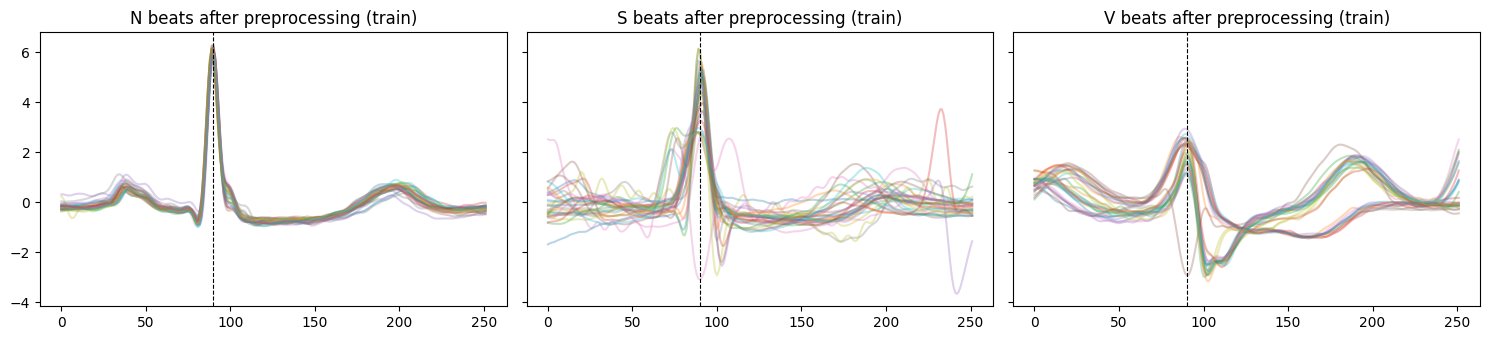

In [11]:
d = np.load(f'{PROC_DIR}/train.npz')
X, cls = d['X'], d['cls']

print("Shape:", X.shape)
print("Per-beat mean (should be ~0):", X.mean(axis=1)[:5].round(4))
print("Per-beat std  (should be ~1):", X.std(axis=1)[:5].round(4))
print("Any NaN?", np.isnan(X).any(), "| Any NaN in RR?", np.isnan(d['rr']).any())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, c in zip(axes, ['N', 'S', 'V']):
    idx = np.where(cls == c)[0][:30]
    for i in idx:
        ax.plot(X[i], alpha=0.3)
    ax.axvline(BEFORE, color='k', ls='--', lw=0.8)
    ax.set_title(f'{c} beats after preprocessing (train)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/06_normalized_beats.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
y_train = np.load(f'{PROC_DIR}/train.npz')['y']
n, n0, n1 = len(y_train), (y_train == 0).sum(), (y_train == 1).sum()

class_weight = {0: n / (2 * n0), 1: n / (2 * n1)}
print("Normal:", n0, "| Abnormal:", n1)
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})

with open(f'{RES_DIR}/class_weights.json', 'w') as f:
    json.dump({str(k): float(v) for k, v in class_weight.items()}, f, indent=2)

Normal: 34412 | Abnormal: 4603
Class weights: {0: np.float64(0.567), 1: np.float64(4.238)}
